# Issue #206 — fixed-N7 constrained ticket policy

This executed notebook is the thin decision layer over `src/ticket_policy/fixed_n7.py`. It verifies the immutable package, shows the preregistered decision, and renders the K/performance and concentration surfaces. Every ticket independently selects exactly seven distinct matches from the full issue pool.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parents[2]
sys.path.insert(0, str(ROOT / 'src'))
from ticket_policy.fixed_n7 import K_GRID, verify
PACKAGE = ROOT / 'results' / 'issue-206'
verification = verify(PACKAGE)
verification

{'status': 'PASS',
 'files': 16,
 'tickets': 243648,
 'issues': 188,
 'fallback_trace_rows': 188,
 'manifest_sha256': '93df8e5f749b6e88203592ac945e1eb6a25a3c82c6502304a9845fefda971e96',
 'disposition': 'INHERIT_MATCHED_MARKET_CONTROL'}

In [2]:
decision = json.loads((PACKAGE / 'decision.json').read_text(encoding='utf-8'))
surface = pd.read_csv(PACKAGE / 'policy_surface.csv')
print(json.dumps(decision, ensure_ascii=False, indent=2))
surface.loc[surface['split'].eq('CV_2023'), [
    'policy', 'K', 'expected_roi', 'realized_roi',
    'matched_lift_realized_roi_vs_control', 'ticket_coverage',
    'mean_pair_match_overlap_share', 'mean_ticket_stake_hhi'
]].reset_index(drop=True)

{
  "disposition": "INHERIT_MATCHED_MARKET_CONTROL",
  "evaluation_split": "CV_2023",
  "fallback_mixed_no_worse": true,
  "fallback_mixed_test_realized_lift": 0.0,
  "fallback_mixed_test_realized_roi": -0.7105015072004601,
  "fallback_mixed_test_ticket_coverage_lift": 0.0,
  "final_capital_authority": false,
  "global_fallback_reason": "VALIDATION_LCB_NOT_POSITIVE",
  "inherited_policy": "MARKET_Q_WOR_K64",
  "label_boundary": "year < 2025 only; 2025-04+ labels are nulled before inference",
  "learned_gate_enabled": false,
  "locked_fallback_issues": 75,
  "locked_issues": 75,
  "matched_control_test_realized_roi": -0.7105015072004601,
  "penalized_utility": -0.14147547736836608,
  "preregistered_gain_present": false,
  "selected_K": 64,
  "selected_policy": "LOGIT_Q_WOR",
  "selection_seed": 206001,
  "selection_split": "CV_2022",
  "stage_3_handoff_only": true,
  "validation_expected_lift": -0.8700253243709734,
  "validation_lift_ci95": [
    -0.6907677806786185,
    1.7170490452632

,policy,K,expected_roi,realized_roi,matched_lift_realized_roi_vs_control,ticket_coverage,mean_pair_match_overlap_share,mean_ticket_stake_hhi
0,FALLBACK_MIXED,64,0.719595,-0.710502,0.000000,1.000000,0.039865,0.015625
1,LOGIT_Q_WOR,16,-0.172451,-1.000000,0.000000,1.000000,0.040779,0.062500
2,LOGIT_Q_WOR,32,-0.172979,-0.003281,0.417722,1.000000,0.040019,0.031250
3,LOGIT_Q_WOR,64,-0.173144,-0.299320,0.411181,1.000000,0.040207,0.015625
4,MARKET_OVERLAP_CAP_Q_WOR,16,5.741364,-1.000000,0.000000,1.000000,0.049481,0.062500
5,MARKET_OVERLAP_CAP_Q_WOR,32,4.217199,0.496646,0.917649,1.000000,0.045596,0.031250
6,MARKET_OVERLAP_CAP_Q_WOR,64,2.899268,-0.089386,0.621115,1.000000,0.042031,0.015625
7,MARKET_OVERLAP_PENALIZED_Q_WOR,16,5.645256,-1.000000,0.000000,1.000000,0.047424,0.062500
8,MARKET_OVERLAP_PENALIZED_Q_WOR,32,4.155391,-1.000000,-0.578997,1.000000,0.044376,0.031250
9,MARKET_OVERLAP_PENALIZED_Q_WOR,64,2.864250,-1.000000,-0.289498,1.000000,0.041749,0.015625


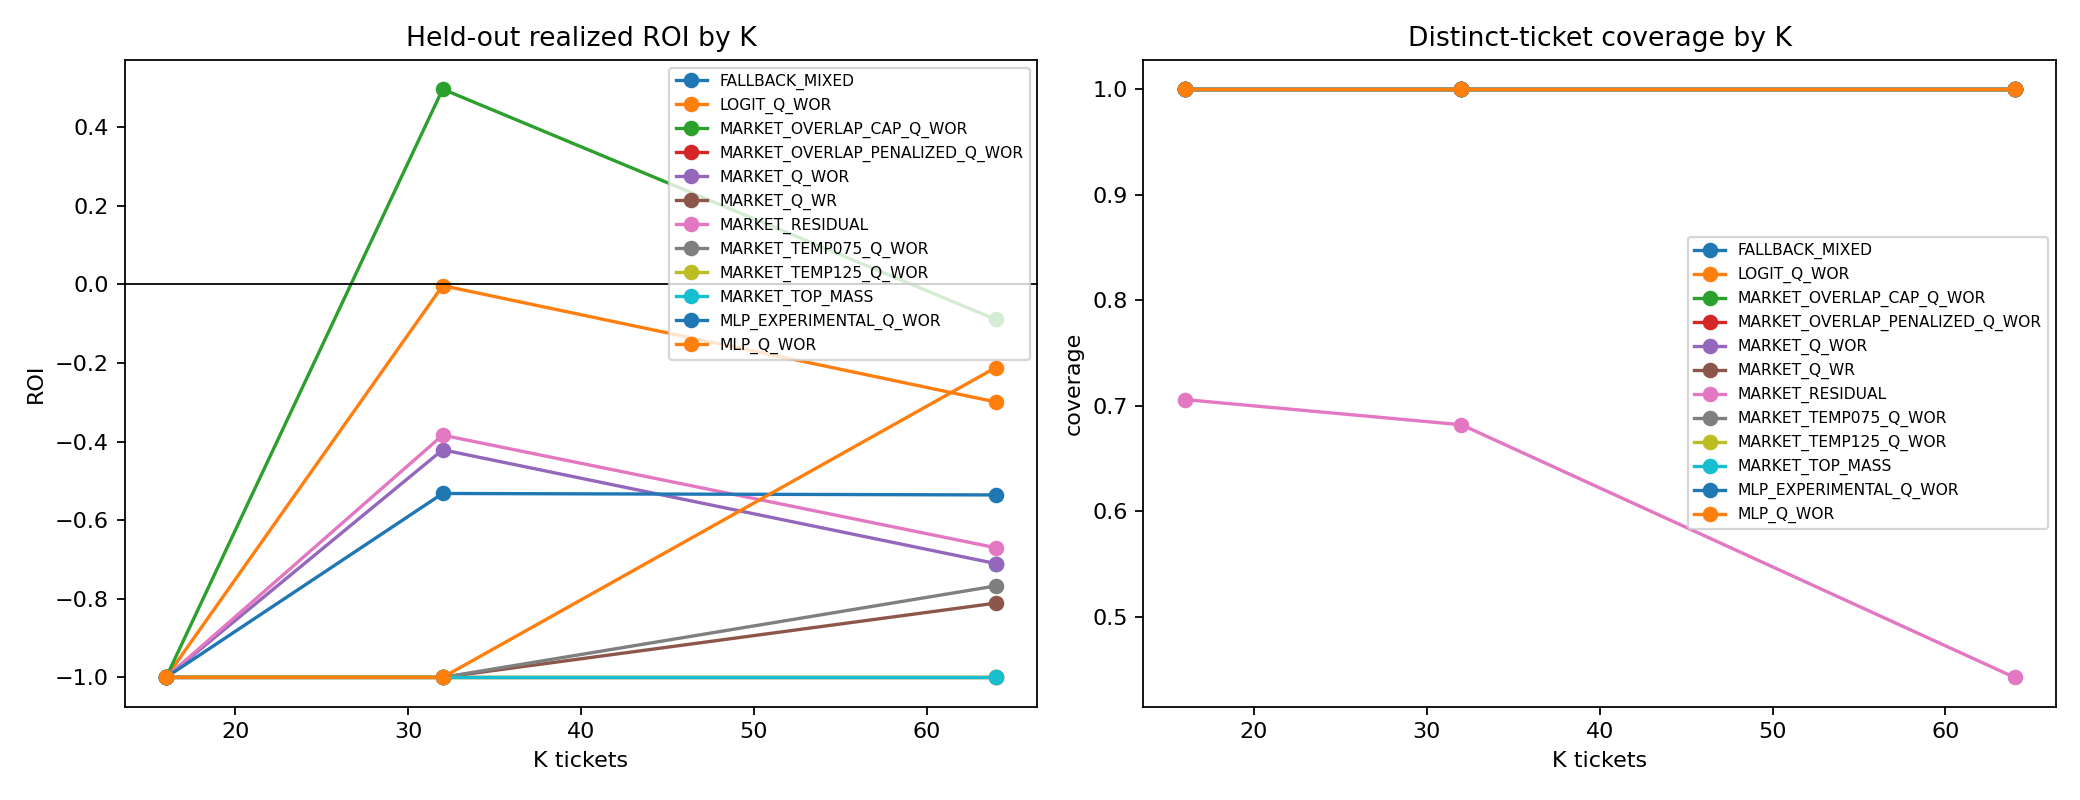

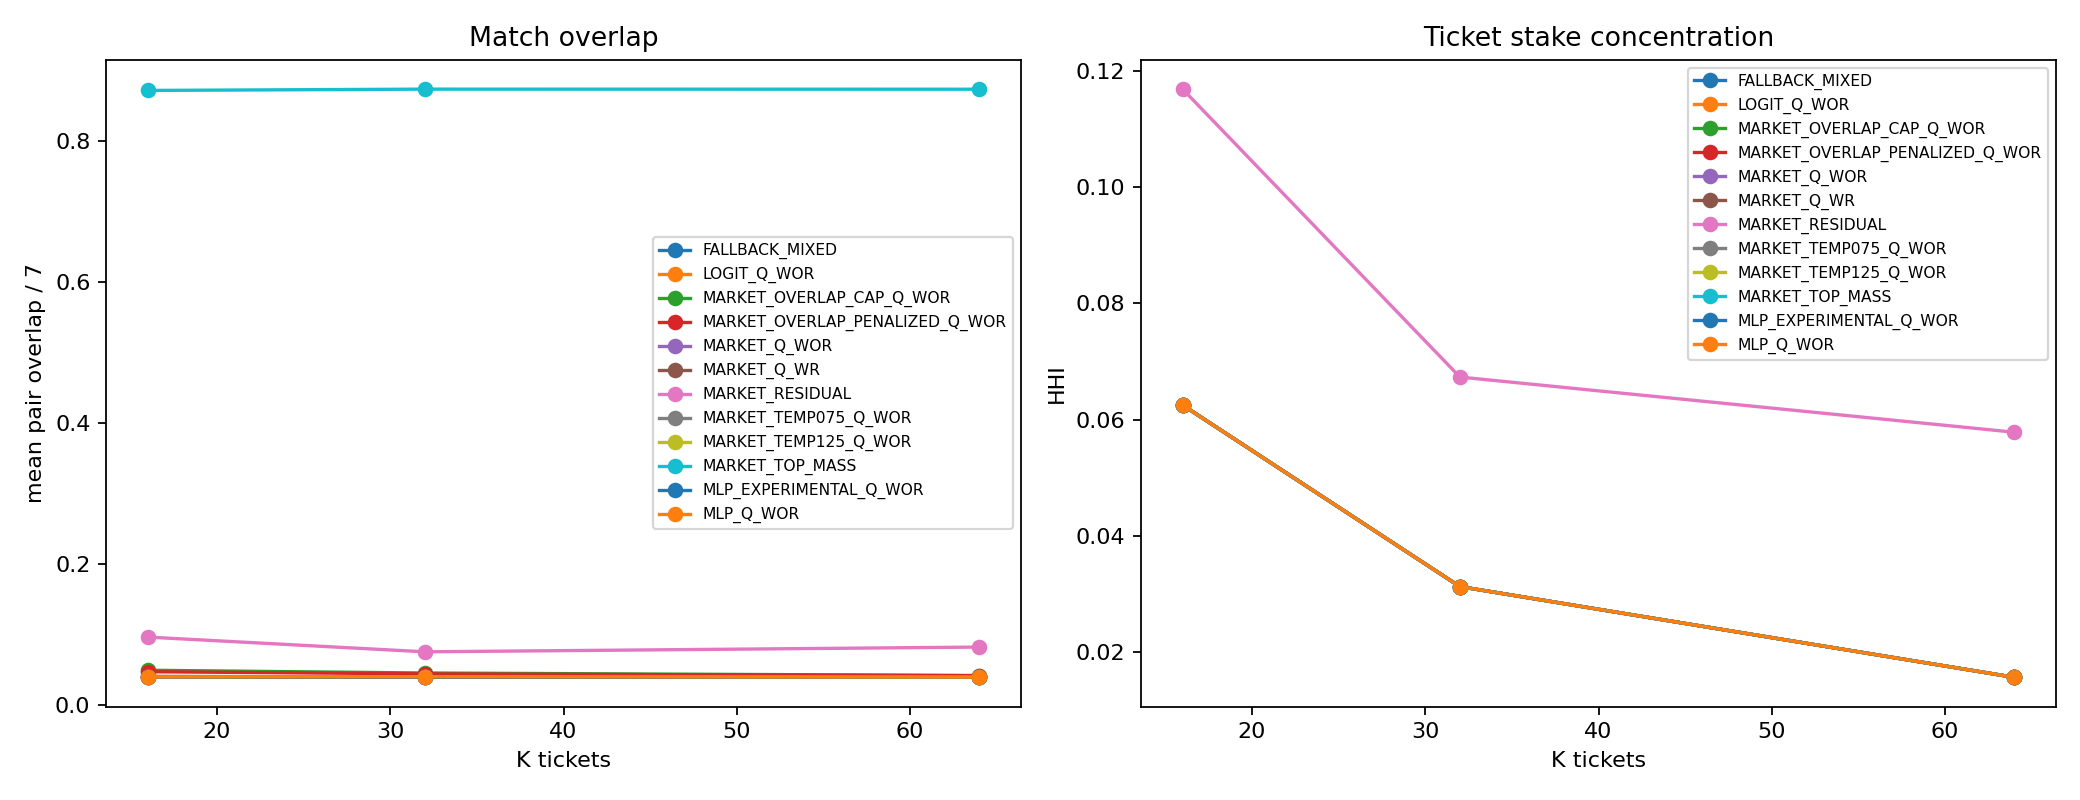

In [3]:
display(Image(filename=str(PACKAGE / 'parameter_performance.png')))
display(Image(filename=str(PACKAGE / 'overlap_concentration.png')))

## Decision reading

The controlling decision is conservative: the learned gate is disabled when the validation issue-bootstrap lower bound and expected lift do not jointly clear zero. The fallback-mixed path therefore copies the matched market control at identical K and stake. Locked 2025/2026 rows contain requested tickets only; labels and official final SP are nulled before inference.